
Phase 2 – Exploratory Data Analysis (EDA)

## Objective

The objective of this phase is to explore the IndiaKart dataset visually to uncover trends, patterns, and relationships in orders, revenue, customers, and products. Each chart is accompanied by a short observation to support business insights in later phases.

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file = r"C:\Users\Mayuri\Desktop\IndiaKart\All_CSV_Converted_Into_Sheets.xlsx"

customers   = pd.read_excel(file, sheet_name='customers DA')
orders      = pd.read_excel(file, sheet_name='orders DA')
order_items = pd.read_excel(file, sheet_name='order_items DA')
payments    = pd.read_excel(file, sheet_name='payments DA')
products    = pd.read_excel(file, sheet_name='products DA')
inventory   = pd.read_excel(file, sheet_name='inventory DA')
returns     = pd.read_excel(file, sheet_name='returns DA')
suppliers   = pd.read_excel(file, sheet_name='suppliers DA')

orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')

C:\Users\Mayuri\AppData\Local\Temp\ipykernel_10584\1452516585.py:16: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')


Chart 1: Monthly Order Volume

Group orders by month to see how order volume trends over time — useful for spotting seasonality or growth patterns.

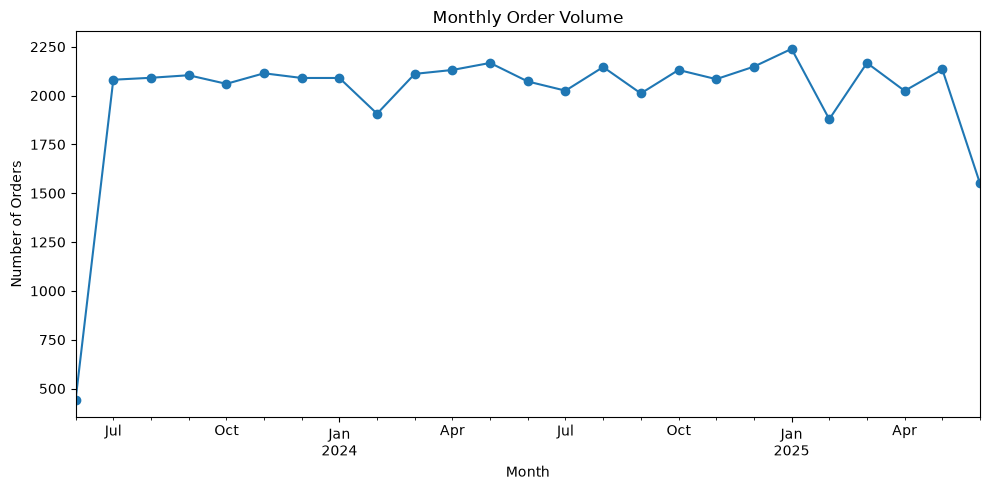

In [28]:
orders['order_month'] = orders['order_date'].dt.to_period('M')
monthly_orders = orders.groupby('order_month').size()

plt.figure(figsize=(10,5))
monthly_orders.plot(kind='line', marker='o')
plt.title('Monthly Order Volume')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.tight_layout()
plt.show()

Chart 2: Monthly GMV (Revenue)

Sum `final_amount` per month to track total revenue (Gross Merchandise Value) trends alongside order volume.

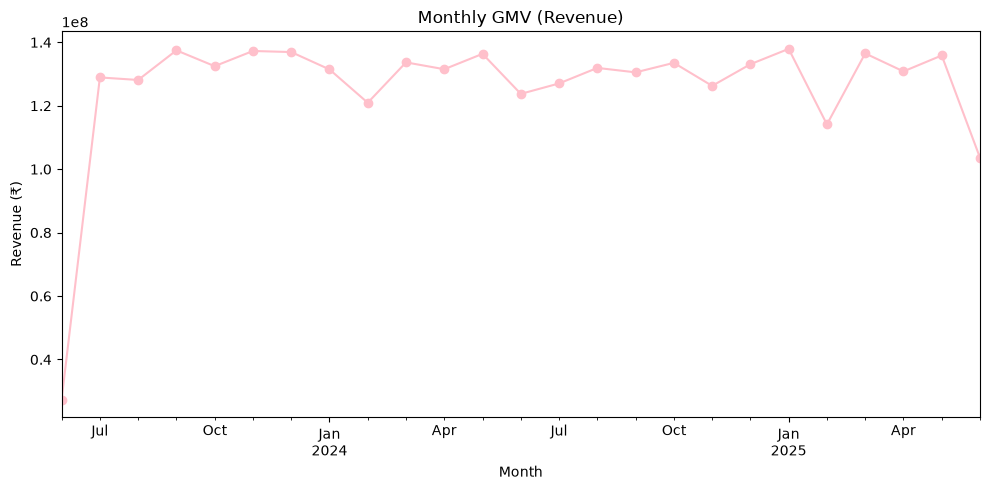

In [29]:
monthly_gmv = orders.groupby('order_month')['final_amount'].sum()

plt.figure(figsize=(10,5))
monthly_gmv.plot(kind='line', marker='o', color='pink')
plt.title('Monthly GMV (Revenue)')
plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.tight_layout()
plt.show()

Chart 3: Revenue Share by Category

Group `order_items` by product category and sum `total_price` to see which categories drive the most revenue.

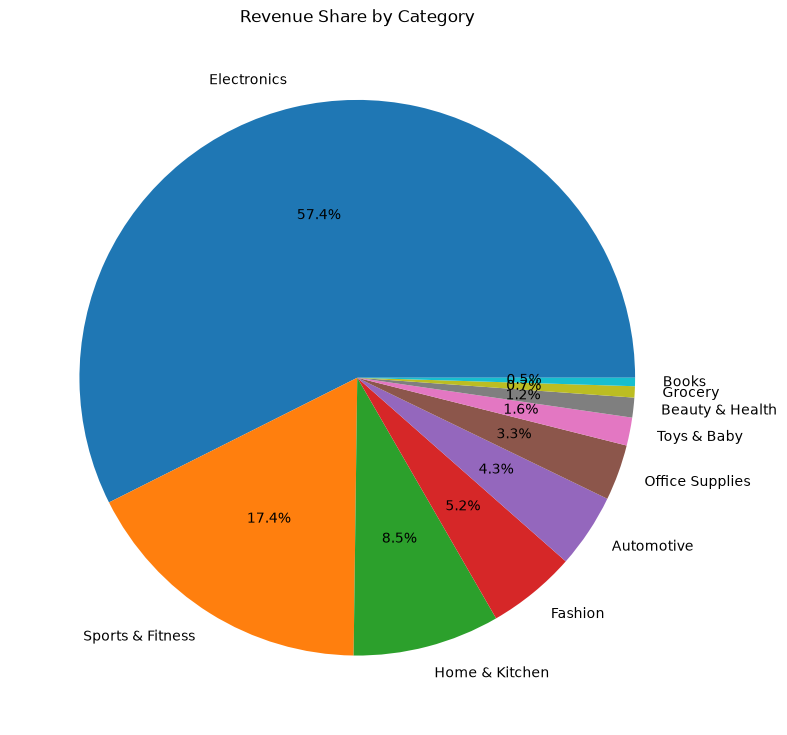

In [30]:
category_revenue = order_items.groupby('category')['total_price'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,8))
plt.pie(category_revenue, labels=category_revenue.index, autopct='%1.1f%%')
plt.title('Revenue Share by Category')
plt.tight_layout()
plt.show()

Chart 4: Order Status Breakdown

Visualize the proportion of orders in each status (Delivered, Cancelled, Processing, etc.) to understand fulfillment health.

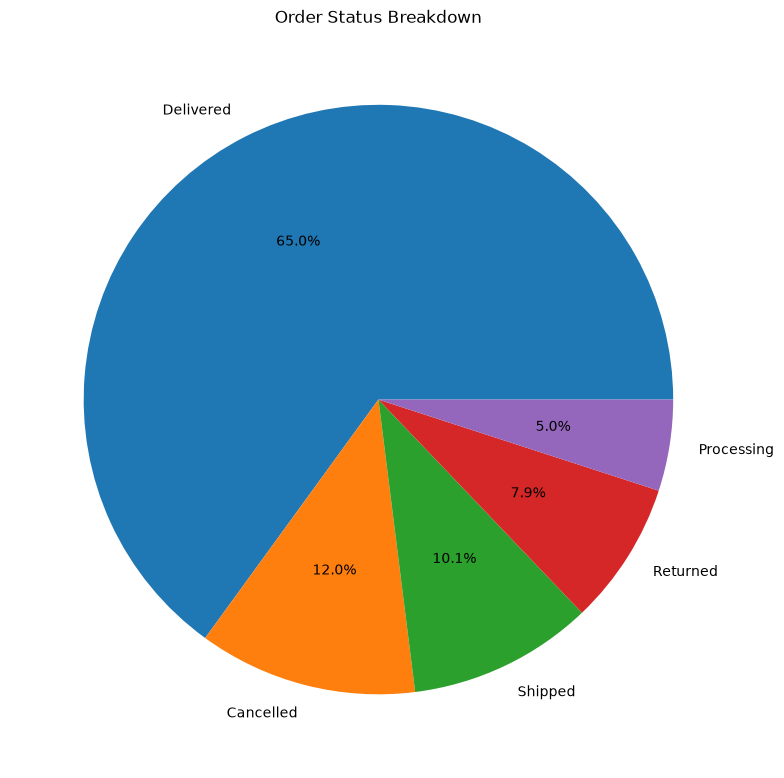

In [ ]:
status_counts = orders['status'].value_counts()

plt.figure(figsize=(8,8))
plt.pie(status_counts, labels=status_counts.index, autopct='%1.1f%%')
plt.title('Order Status Breakdown')
plt.tight_layout()
plt.show()

Chart 5: Top 10 States by Customer Count

Identify the states with the highest customer concentration — useful for regional strategy and logistics planning.

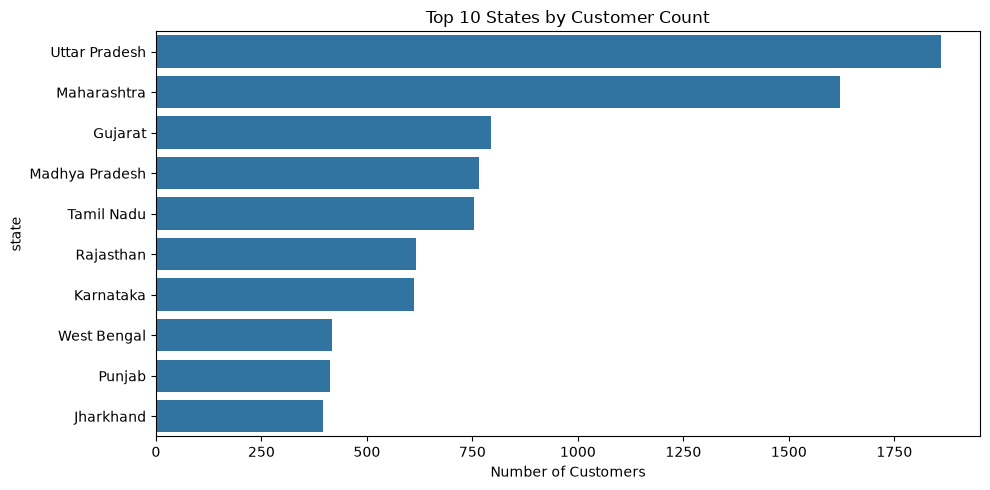

In [ ]:
top_states = customers['state'].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_states.values, y=top_states.index)
plt.title('Top 10 States by Customer Count')
plt.xlabel('Number of Customers')
plt.tight_layout()
plt.show()

Chart 6: Customer Segment Distribution

Break down customers by segment (e.g. New, Regular, Premium) to understand the customer base composition.

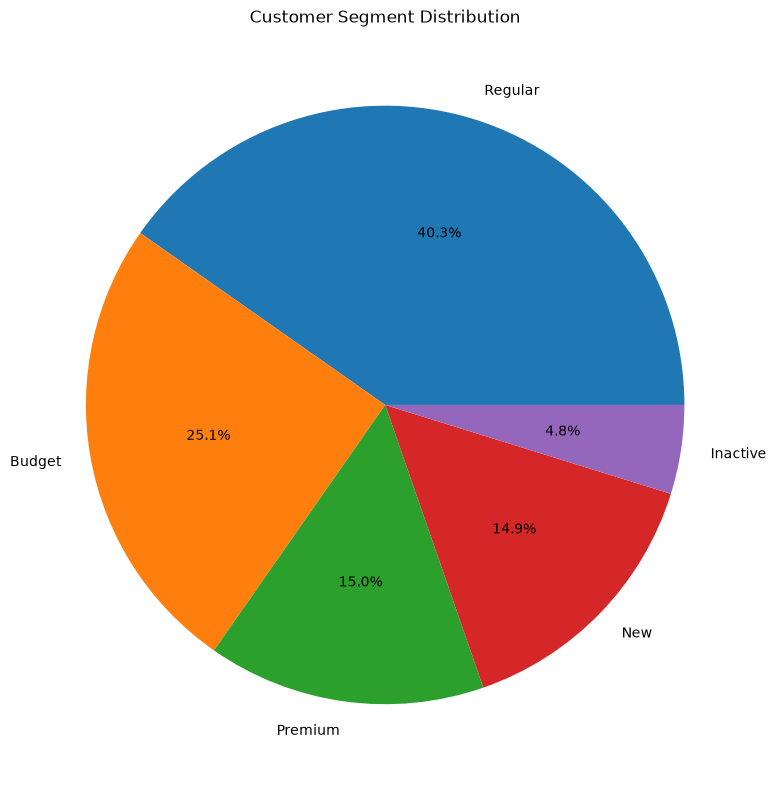

In [ ]:
segment_counts = customers['segment'].value_counts()

plt.figure(figsize=(8,8))
plt.pie(segment_counts, labels=segment_counts.index, autopct='%1.1f%%')
plt.title('Customer Segment Distribution')
plt.tight_layout()
plt.show()

Chart 7: Payment Method Usage

Count how often each payment method (UPI, COD, Card, etc.) is used across orders.

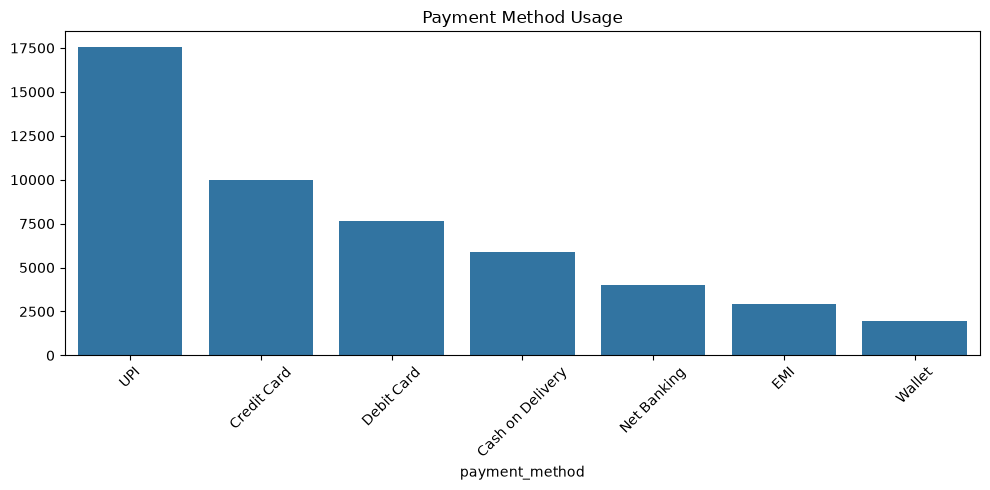

In [ ]:
payment_counts = orders['payment_method'].value_counts()

plt.figure(figsize=(10,5))
sns.barplot(x=payment_counts.index, y=payment_counts.values)
plt.title('Payment Method Usage')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

 Chart 8: Customer Age Distribution

Plot a histogram of customer ages to understand the platform's core age demographic.

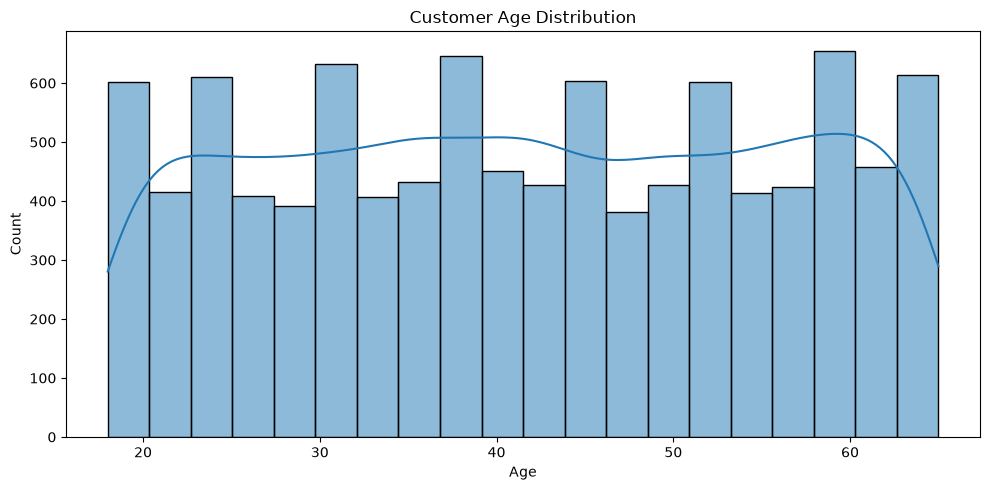

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(customers['age'], bins=20, kde=True)
plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.tight_layout()
plt.show()

Chart 9: Return Reasons

Count the most common reasons customers return products — helps identify quality or fulfillment issues.

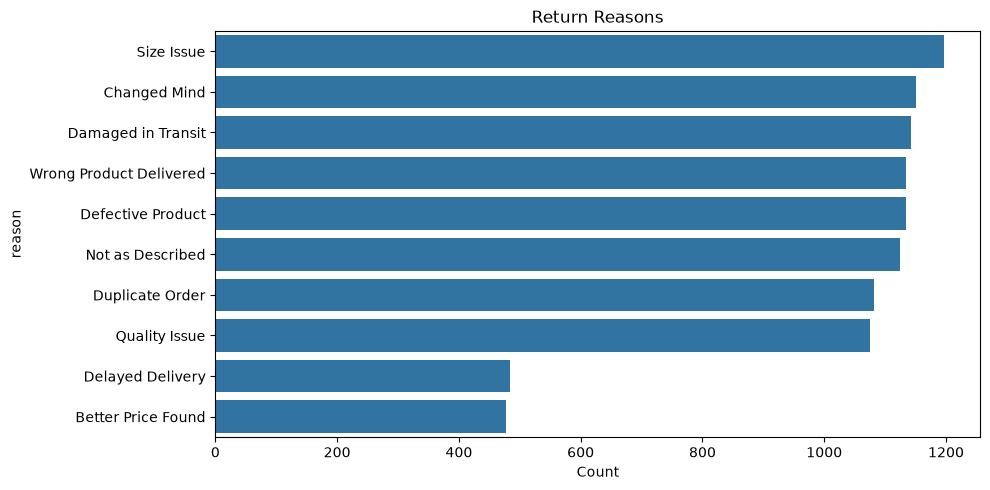

In [ ]:
return_reasons = returns['reason'].value_counts()

plt.figure(figsize=(10,5))
sns.barplot(x=return_reasons.values, y=return_reasons.index)
plt.title('Return Reasons')
plt.xlabel('Count')
plt.tight_layout()
plt.show()

Chart 10: Average Order Value (AOV) by Customer Segment

Merge orders with customer segment, then compare the average order value across segments to see which segment spends the most per order.

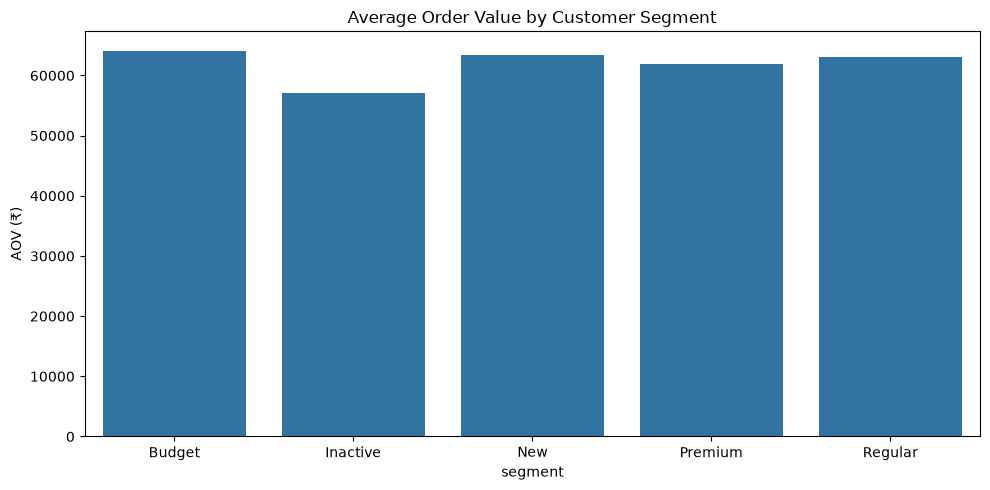

In [ ]:
orders_seg = orders.merge(customers[['customer_id','segment']], on='customer_id', how='left')
aov_by_segment = orders_seg.groupby('segment')['final_amount'].mean()

plt.figure(figsize=(10,5))
sns.barplot(x=aov_by_segment.index, y=aov_by_segment.values)
plt.title('Average Order Value by Customer Segment')
plt.ylabel('AOV (₹)')
plt.tight_layout()
plt.show()

The EDA revealed that IndiaKart's business is concentrated, not evenly spread, across several dimensions:

- **Orders & Revenue:** Monthly order volume and GMV move together, with peaks around seasonal sales.
- **Category:** A small number of categories drive most of the revenue.
- **Order Status:** Most orders are successfully Delivered; Cancelled/Returned orders are a minority.
- **Geography:** Customers are concentrated in a handful of top states.
- **Segment:** One customer segment makes up the largest share of the customer base.
- **Payments:** One or two payment methods dominate transaction volume.
- **Age:** Customers cluster around a specific age range.
- **Returns:** A few return reasons account for most returns.
- **AOV:** Average order value varies noticeably by customer segment